# Cortical Depth Profile Confidence Interval QC

This notebook evaluates the consistency of regional cortical depth profiles
using the mean profile and 95% confidence interval from the GM/WM interface
to the pial surface.


In [152]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Import

In [153]:
subjects = {
    "D0007": {
        "profile_dir": Path(
            "/mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/D0007/analysis/profiles"
        ),
        "qa_dir": Path(
            "/mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/D0007/analysis/regional_profiles"
        ),
        "file_style": "new",
    },

    "S00775": {
        "profile_dir": Path(
            "/mnt/newStor/paros/paros_WORK/xintong/test/existing_pipeline/output/S00775/adc/adc_cols_by_column"
        ),
        "qa_dir": Path(
            "/mnt/newStor/paros/paros_WORK/xintong/test/existing_pipeline/output/S00775/adc/plots_QA"
        ),
        "file_style": "historical",
    },
}

In [154]:
for subject, config in subjects.items():

    print(f"\n{subject}")

    for name in [
        "profile_dir",
        "qa_dir",
    ]:

        path = config[name]

        print(
            f"{name:15s}",
            path.exists(),
            path,
        )


D0007
profile_dir     True /mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/D0007/analysis/profiles
qa_dir          True /mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/D0007/analysis/regional_profiles

S00775
profile_dir     True /mnt/newStor/paros/paros_WORK/xintong/test/existing_pipeline/output/S00775/adc/adc_cols_by_column
qa_dir          True /mnt/newStor/paros/paros_WORK/xintong/test/existing_pipeline/output/S00775/adc/plots_QA


In [155]:
qa_data = {}

for subject, config in subjects.items():

    qa_csv = (
        config["qa_dir"]
        / f"{subject}_profiles_QA_adc.csv"
    )

    print(f"\nLoading {subject}")
    print(qa_csv)

    qa_data[subject] = pd.read_csv(
        qa_csv
    )

    print(
        "Shape:",
        qa_data[subject].shape,
    )

    print(
        "Columns:",
        list(
            qa_data[subject].columns
        ),
    )


Loading D0007
/mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/D0007/analysis/regional_profiles/D0007_profiles_QA_adc.csv
Shape: (1428, 7)
Columns: ['hemi', 'region', 'depth_index', 'mean', 'ci_lower', 'ci_upper', 'n_trajectories']

Loading S00775
/mnt/newStor/paros/paros_WORK/xintong/test/existing_pipeline/output/S00775/adc/plots_QA/S00775_profiles_QA_adc.csv
Shape: (1428, 7)
Columns: ['hemi', 'region', 'depth_index', 'mean', 'ci_lower', 'ci_upper', 'n_columns']


In [156]:
for subject, df in qa_data.items():

    print(f"\n===== {subject} =====")

    print(
        "Hemispheres:",
        sorted(df["hemi"].unique()),
    )

    print(
        "Regions:",
        df["region"].nunique(),
    )

    print(
        "Hemisphere-region combinations:",
        df[["hemi", "region"]]
        .drop_duplicates()
        .shape[0],
    )

    print(
        "Depth indices:",
        sorted(df["depth_index"].unique()),
    )


===== D0007 =====
Hemispheres: ['lh', 'rh']
Regions: 34
Hemisphere-region combinations: 68
Depth indices: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20)]

===== S00775 =====
Hemispheres: ['lh', 'rh']
Regions: 34
Hemisphere-region combinations: 68
Depth indices: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20)]


In [157]:
def load_profiles(
    subject,
    hemi,
    region,
    metric="adc",
):

    config = subjects[subject]

    if config["file_style"] == "historical":

        filename = (
            f"{subject}_"
            f"{hemi}_"
            f"{region}_"
            f"cols_{metric}.csv"
        )

    else:

        filename = (
            f"{subject}_"
            f"{hemi}_"
            f"{region}_"
            f"{metric}.csv"
        )

    profile_file = (
        config["profile_dir"]
        / filename
    )

    if not profile_file.exists():

        raise FileNotFoundError(
            f"Profile file not found: "
            f"{profile_file}"
        )

    profiles = np.loadtxt(
        profile_file,
        delimiter=",",
    )

    if profiles.ndim == 1:

        profiles = profiles.reshape(
            1,
            -1,
        )

    return profiles

In [158]:
region = "transversetemporal"
hemi = "lh"

profile_data = {}

for subject in subjects:
    profile_data[subject] = load_profiles(
        subject,
        hemi,
        region,
    )

    print(
        subject,
        profile_data[subject].shape,
    )

D0007 (702, 21)
S00775 (805, 21)


## Profile completeness

In [159]:
for subject, df in qa_data.items():

    print("=" * 70)
    print(subject)
    print("=" * 70)

    depth_counts = (
        df.groupby(["hemi", "region"])["depth_index"]
          .nunique()
          .reset_index(name="n_depths")
    )

    print(
        "Hemisphere-region combinations:",
        len(depth_counts),
    )

    print("\nDepth count distribution:")
    print(
        depth_counts["n_depths"]
        .value_counts()
        .sort_index()
    )

    incomplete = depth_counts[
        depth_counts["n_depths"] != 21
    ]

    print(
        "\nIncomplete profiles:",
        len(incomplete),
    )

    if len(incomplete) > 0:
        display(incomplete)

    print()

D0007
Hemisphere-region combinations: 68

Depth count distribution:
n_depths
21    68
Name: count, dtype: int64

Incomplete profiles: 0

S00775
Hemisphere-region combinations: 68

Depth count distribution:
n_depths
21    68
Name: count, dtype: int64

Incomplete profiles: 0



### Result

Both subjects contained complete cortical depth profiles across all 68 hemisphere-region combinations, with 21 depth samples per profile.

## Within-region trajectory variability

Trajectory-level variability was evaluated within each cortical region using the standard deviation (SD) and coefficient of variation (CV) of the ADC/MD profiles.

SD measures the absolute dispersion among trajectories, whereas CV measures dispersion relative to the regional mean signal. Because the goal of this section is to identify relatively stable and variable cortical regions, representative regions are selected according to CV rather than mean ADC/MD.

The analysis is performed independently for D0007 and S00775. With only two representative subjects, the results are used for descriptive quality control rather than formal between-subject comparison.


### Calculate regional trajectory variability

For every hemisphere-region combination, trajectory-level ADC profiles are used to calculate the mean profile, SD, and CV across the 21 cortical depth samples.

A single region-level CV is then calculated by averaging the mean CV from the left and right hemispheres. This value is used only to rank regions within each subject.

In [160]:
regional_variability_rows = []
variability_profiles = {}

for subject in subjects:

    variability_profiles[subject] = {}

    regions = sorted(
        qa_data[subject]["region"].unique()
    )

    for region in regions:

        variability_profiles[subject][region] = {}

        for hemi in ["lh", "rh"]:

            profiles = load_profiles(
                subject,
                hemi,
                region,
                metric="adc",
            )

            mean_profile = profiles.mean(axis=0)

            sd_profile = profiles.std(
                axis=0,
                ddof=1,
            )

            cv_profile = (
                sd_profile
                / np.abs(mean_profile)
            )

            variability_profiles[subject][region][hemi] = {
                "profiles": profiles,
                "mean": mean_profile,
                "sd": sd_profile,
                "cv": cv_profile,
            }

            regional_variability_rows.append(
                {
                    "subject": subject,
                    "region": region,
                    "hemi": hemi,
                    "n_trajectories": profiles.shape[0],
                    "mean_adc": mean_profile.mean(),
                    "mean_sd": sd_profile.mean(),
                    "mean_cv": cv_profile.mean(),
                }
            )

regional_variability = pd.DataFrame(
    regional_variability_rows
)

display(
    regional_variability.head()
)

,subject,region,hemi,n_trajectories,mean_adc,mean_sd,mean_cv
0,D0007,bankssts,lh,1201,0.000794,0.000203,0.238632
1,D0007,bankssts,rh,1085,0.000838,0.000222,0.254261
2,D0007,caudalanteriorcingulate,lh,820,0.000970,0.000210,0.218213
3,D0007,caudalanteriorcingulate,rh,1010,0.001007,0.000254,0.252689
4,D0007,caudalmiddlefrontal,lh,3135,0.000920,0.000193,0.202550


### Rank regions by relative variability

Regions are ranked independently within each subject using bilateral mean CV.

The ten regions with the lowest CV and the ten regions with the highest CV are listed to provide an overview of relatively consistent and relatively variable trajectory profiles.

For visualization in the following section, two low-CV and two high-CV regions are selected from these rankings.

The entorhinal cortex is excluded from representative-region selection because of previously identified sampling sensitivity.

In [161]:
excluded_regions = {
    "entorhinal",
}

region_cv_ranking = (
    regional_variability[
        ~regional_variability["region"].isin(
            excluded_regions
        )
    ]
    .groupby(
        ["subject", "region"],
        as_index=False,
    )
    .agg(
        mean_cv=("mean_cv", "mean"),
        mean_sd=("mean_sd", "mean"),
        mean_adc=("mean_adc", "mean"),
        total_trajectories=(
            "n_trajectories",
            "sum",
        ),
    )
)

selected_regions = {}

for subject in subjects:

    ranking = (
        region_cv_ranking[
            region_cv_ranking["subject"] == subject
        ]
        .sort_values("mean_cv")
        .reset_index(drop=True)
    )

    print(f"\n===== {subject}: Lowest CV regions =====")

    display(
        ranking.head(10)[
            [
                "region",
                "mean_cv",
                "mean_sd",
                "mean_adc",
                "total_trajectories",
            ]
        ].style.format(
            {
                "mean_cv": "{:.3f}",
                "mean_sd": "{:.6f}",
                "mean_adc": "{:.6f}",
            }
        )
    )

    print(f"\n===== {subject}: Highest CV regions =====")

    display(
        ranking.tail(10)
        .sort_values(
            "mean_cv",
            ascending=False,
        )[
            [
                "region",
                "mean_cv",
                "mean_sd",
                "mean_adc",
                "total_trajectories",
            ]
        ].style.format(
            {
                "mean_cv": "{:.3f}",
                "mean_sd": "{:.6f}",
                "mean_adc": "{:.6f}",
            }
        )
    )

    lowest = ranking.head(2).copy()
    lowest["group"] = "Low CV"

    highest = (
        ranking.tail(2)
        .sort_values("mean_cv")
        .copy()
    )
    highest["group"] = "High CV"

    selected_regions[subject] = pd.concat(
        [lowest, highest],
        ignore_index=True,
    )


===== D0007: Lowest CV regions =====


,region,mean_cv,mean_sd,mean_adc,total_trajectories
0,rostralmiddlefrontal,0.187,0.000175,0.000911,14148
1,posteriorcingulate,0.192,0.000172,0.000876,2977
2,superiorfrontal,0.195,0.000186,0.000934,17731
3,caudalmiddlefrontal,0.197,0.000185,0.000909,5763
4,parsorbitalis,0.208,0.000183,0.000845,1759
5,parsopercularis,0.210,0.000196,0.000895,3956
6,parstriangularis,0.216,0.000197,0.000896,3433
7,precuneus,0.223,0.000195,0.000837,10183
8,cuneus,0.225,0.000224,0.000976,4623
9,paracentral,0.226,0.000192,0.000835,4321



===== D0007: Highest CV regions =====


,region,mean_cv,mean_sd,mean_adc,total_trajectories
32,inferiortemporal,0.391,0.000285,0.000711,7378
31,postcentral,0.365,0.000366,0.001003,11857
30,transversetemporal,0.327,0.000350,0.001004,1212
29,superiortemporal,0.321,0.000312,0.000923,9741
28,medialorbitofrontal,0.316,0.000265,0.000827,5779
27,temporalpole,0.295,0.000311,0.001041,1242
26,parahippocampal,0.294,0.000250,0.000813,1940
25,supramarginal,0.292,0.000287,0.000929,10651
24,isthmuscingulate,0.287,0.000246,0.000839,2741
23,middletemporal,0.285,0.000241,0.000810,7097



===== S00775: Lowest CV regions =====


,region,mean_cv,mean_sd,mean_adc,total_trajectories
0,bankssts,0.227,0.000194,0.000823,2917
1,parsopercularis,0.237,0.000201,0.000825,4115
2,parstriangularis,0.237,0.000203,0.000834,4447
3,supramarginal,0.251,0.000220,0.000837,10704
4,posteriorcingulate,0.254,0.000201,0.000788,3246
5,postcentral,0.274,0.000241,0.000844,12235
6,transversetemporal,0.279,0.000242,0.000856,1412
7,precentral,0.280,0.000225,0.000773,13949
8,inferiorparietal,0.281,0.000242,0.000837,12108
9,paracentral,0.287,0.000250,0.000842,4608



===== S00775: Highest CV regions =====


,region,mean_cv,mean_sd,mean_adc,total_trajectories
32,lateraloccipital,0.719,0.000593,0.000817,12879
31,inferiortemporal,0.654,0.000487,0.000749,7549
30,temporalpole,0.592,0.000641,0.001040,1022
29,isthmuscingulate,0.518,0.000497,0.000938,2459
28,superiorparietal,0.491,0.000440,0.000883,14088
27,lingual,0.478,0.000513,0.001040,8339
26,parahippocampal,0.465,0.000439,0.000915,1645
25,cuneus,0.444,0.000391,0.000872,4514
24,medialorbitofrontal,0.416,0.000403,0.000955,5307
23,frontalpole,0.398,0.000398,0.000989,725


### Variability summary

The following table summarizes trajectory variability for the selected low-CV and high-CV regions.

Mean SD describes absolute trajectory dispersion, while mean CV describes relative dispersion after accounting for differences in the regional mean signal. These values are presented descriptively for QC and are not used for statistical comparison between subjects.

In [162]:
selected_names = []

for subject, selected in selected_regions.items():

    for _, row in selected.iterrows():

        selected_names.append(
            {
                "subject": subject,
                "region": row["region"],
                "group": row["group"],
            }
        )

selected_names = pd.DataFrame(
    selected_names
)

selected_summary = (
    regional_variability
    .merge(
        selected_names,
        on=["subject", "region"],
        how="inner",
    )
    [
        [
            "subject",
            "group",
            "region",
            "hemi",
            "n_trajectories",
            "mean_adc",
            "mean_sd",
            "mean_cv",
        ]
    ]
    .sort_values(
        [
            "subject",
            "group",
            "region",
            "hemi",
        ]
    )
    .reset_index(drop=True)
)

display(
    selected_summary.style.format(
        {
            "mean_adc": "{:.6f}",
            "mean_sd": "{:.6f}",
            "mean_cv": "{:.3f}",
        }
    )
)

,subject,group,region,hemi,n_trajectories,mean_adc,mean_sd,mean_cv
0,D0007,High CV,inferiortemporal,lh,3925,0.000694,0.000250,0.350
1,D0007,High CV,inferiortemporal,rh,3453,0.000728,0.000320,0.431
2,D0007,High CV,postcentral,lh,5808,0.001034,0.000369,0.357
3,D0007,High CV,postcentral,rh,6049,0.000972,0.000362,0.372
4,D0007,Low CV,posteriorcingulate,lh,1504,0.000845,0.000168,0.194
5,D0007,Low CV,posteriorcingulate,rh,1473,0.000907,0.000175,0.190
6,D0007,Low CV,rostralmiddlefrontal,lh,7074,0.000918,0.000161,0.171
7,D0007,Low CV,rostralmiddlefrontal,rh,7074,0.000905,0.000188,0.203
8,S00775,High CV,inferiortemporal,lh,3919,0.000766,0.000428,0.557
9,S00775,High CV,inferiortemporal,rh,3630,0.000731,0.000546,0.751


### Individual trajectory profiles

To visualize the variability summarized by SD and CV, a subset of approximately 70 individual trajectories is displayed for each selected low-CV and high-CV region.

The subset is used only for visualization, since plotting all trajectories would make the figure difficult to interpret. The full regional mean profile and ±1 SD are overlaid to show the central trend and overall trajectory dispersion.

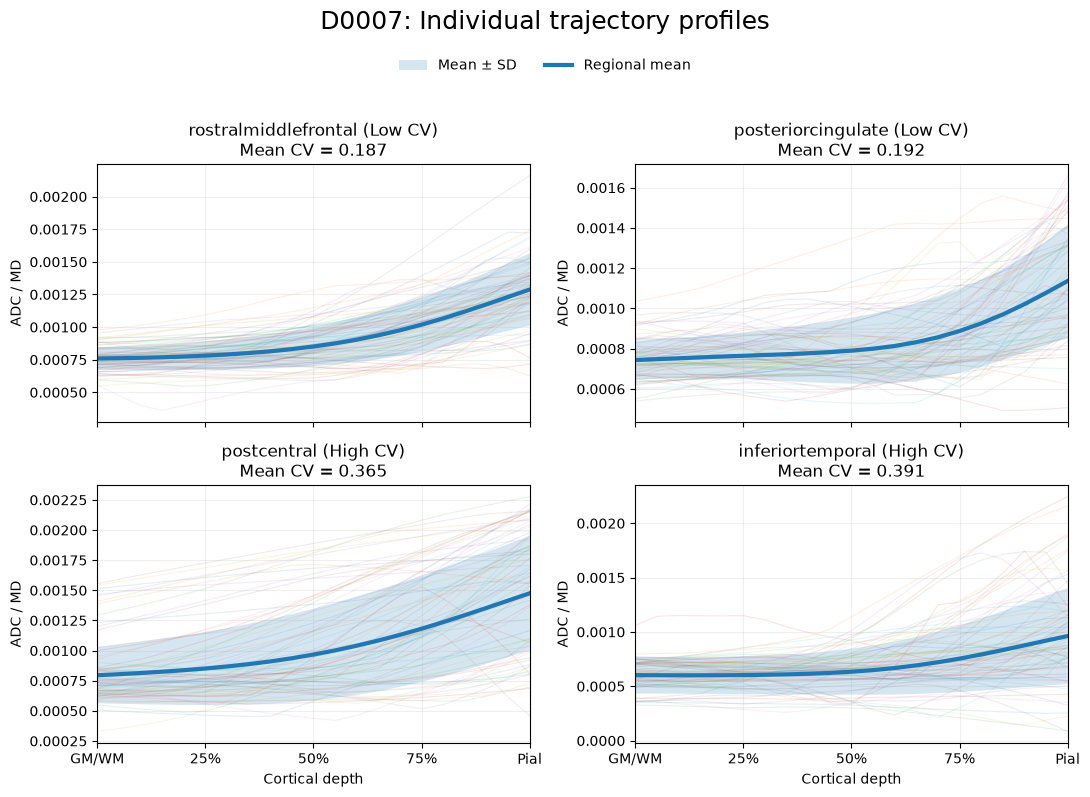

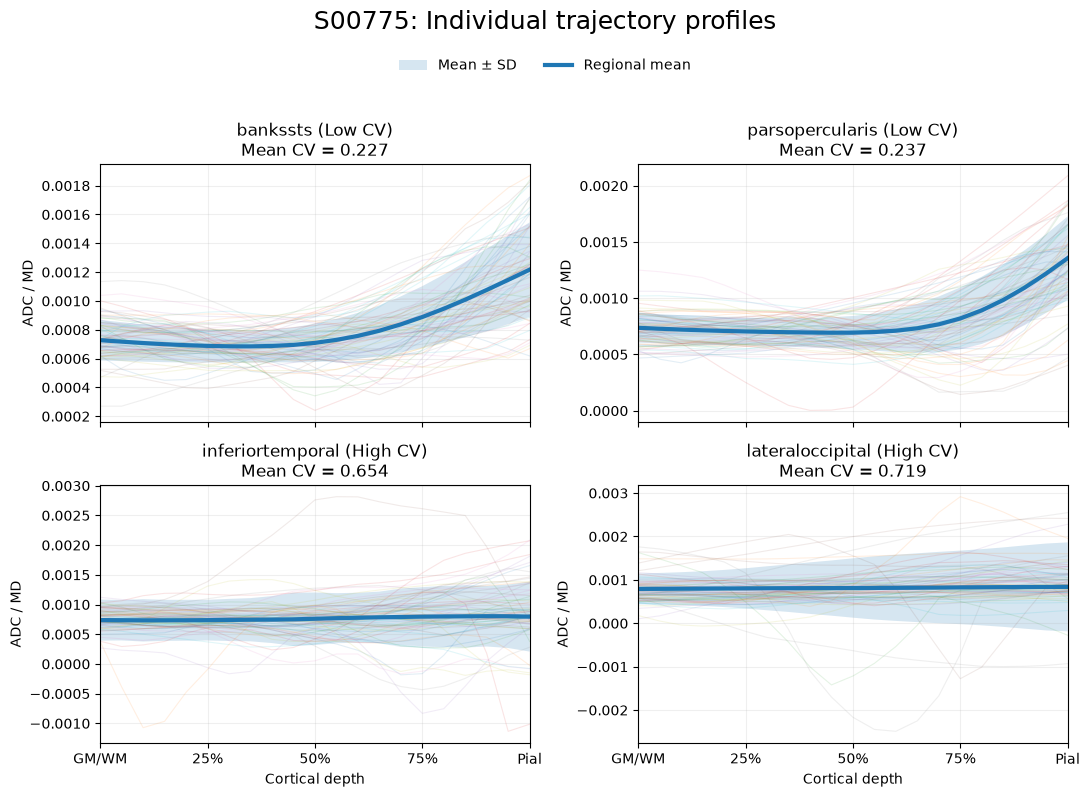

In [163]:
rng = np.random.default_rng(42)
n_display = 70

depth = np.linspace(
    0,
    1,
    21,
)

for subject in subjects:

    selected = selected_regions[subject]

    fig, axes = plt.subplots(
        2,
        2,
        figsize=(11, 8),
        sharex=True,
    )

    axes = axes.ravel()

    for ax, (_, row) in zip(
        axes,
        selected.iterrows(),
    ):

        region = row["region"]
        group = row["group"]
        region_cv = row["mean_cv"]

        profiles = (
            variability_profiles
            [subject]
            [region]
            ["lh"]
            ["profiles"]
        )

        mean_profile = profiles.mean(axis=0)

        sd_profile = profiles.std(
            axis=0,
            ddof=1,
        )

        n = profiles.shape[0]

        display_idx = rng.choice(
            n,
            size=min(
                n_display,
                n,
            ),
            replace=False,
        )

        displayed_profiles = (
            profiles[display_idx]
        )

        # Individual trajectories
        for profile in displayed_profiles:

            ax.plot(
                depth,
                profile,
                alpha=0.12,
                linewidth=0.8,
            )

        # Mean ± SD
        ax.fill_between(
            depth,
            mean_profile - sd_profile,
            mean_profile + sd_profile,
            alpha=0.18,
            label="Mean ± SD",
        )

        # Regional mean
        ax.plot(
            depth,
            mean_profile,
            linewidth=3,
            label="Regional mean",
        )

        ax.set_title(
            f"{region} ({group})\n"
            f"Mean CV = {region_cv:.3f}"
        )

        ax.set_ylabel(
            "ADC / MD"
        )

        ax.set_xlim(
            0,
            1,
        )

        ax.set_xticks(
            [
                0,
                0.25,
                0.5,
                0.75,
                1,
            ]
        )

        ax.set_xticklabels(
            [
                "GM/WM",
                "25%",
                "50%",
                "75%",
                "Pial",
            ]
        )

        ax.grid(
            alpha=0.2
        )

    axes[2].set_xlabel(
        "Cortical depth"
    )

    axes[3].set_xlabel(
        "Cortical depth"
    )

    handles, labels = (
        axes[0].get_legend_handles_labels()
    )

    fig.suptitle(
    f"{subject}: Individual trajectory profiles",
    fontsize=18,
    y=0.99,
)

    fig.legend(
        handles,
        labels,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.945),
        ncol=2,
        frameon=False,
        fontsize=7.5,
        labelspacing=.35,
        handlelength=1.8,
        handletextpad=.5,
    )

    plt.tight_layout(
        rect=[0, 0, 1, 0.92]
    )

    plt.show()

## Representative regional profiles

Regional mean cortical depth profiles and 95% confidence intervals are evaluated to assess the precision of the estimated mean profile across cortical regions.

For each subject, regions are ranked independently according to the average 95% CI width across cortical depth and both hemispheres. Regions with narrow confidence intervals represent more precisely estimated regional mean profiles, while regions with wider confidence intervals indicate greater uncertainty in the estimated mean.

These results are used descriptively for quality control rather than for formal between-subject comparison.

In [164]:
regional_ci_rows = []

for subject, df in qa_data.items():

    temp = df.copy()

    temp["ci_width"] = (
        temp["ci_upper"]
        - temp["ci_lower"]
    )

    region_ci = (
        temp.groupby(
            ["region", "hemi"],
            as_index=False,
        )
        .agg(
            mean_ci_width=(
                "ci_width",
                "mean",
            ),
            mean_adc=(
                "mean",
                "mean",
            ),
        )
    )

    region_ci["subject"] = subject

    regional_ci_rows.append(
        region_ci
    )

regional_ci = pd.concat(
    regional_ci_rows,
    ignore_index=True,
)

In [165]:
regional_ci_bilateral = (
    regional_ci
    .groupby(
        ["subject", "region"],
        as_index=False,
    )
    .agg(
        mean_ci_width=(
            "mean_ci_width",
            "mean",
        ),
        mean_adc=(
            "mean_adc",
            "mean",
        ),
    )
)

In [166]:
selected_ci_regions = {}

for subject in subjects:

    ranking = (
        region_ci_ranking[
            region_ci_ranking["subject"]
            == subject
        ]
        .sort_values("mean_ci_width")
        .reset_index(drop=True)
    )

    print(
        f"\n===== {subject}: Narrowest CI ====="
    )

    display(
        ranking.head(10).style.format(
            {
                "mean_ci_width": "{:.8f}",
                "mean_adc": "{:.6f}",
            }
        )
    )

    print(
        f"\n===== {subject}: Widest CI ====="
    )

    display(
        ranking.tail(10)
        .sort_values(
            "mean_ci_width",
            ascending=False,
        )
        .style.format(
            {
                "mean_ci_width": "{:.8f}",
                "mean_adc": "{:.6f}",
            }
        )
    )

    narrow = ranking.head(2).copy()
    narrow["group"] = "Narrow CI"

    wide = ranking.tail(2).copy()
    wide["group"] = "Wide CI"

    selected_ci_regions[subject] = pd.concat(
        [narrow, wide],
        ignore_index=True,
    )


===== D0007: Narrowest CI =====


,subject,region,mean_ci_width,mean_adc,total_trajectories
0,D0007,superiorfrontal,0.00000776,0.000934,17731
1,D0007,rostralmiddlefrontal,0.00000814,0.000911,14148
2,D0007,precentral,0.00001064,0.000884,14075
3,D0007,lateraloccipital,0.00001069,0.000864,13272
4,D0007,precuneus,0.00001071,0.000837,10183
5,D0007,superiorparietal,0.00001100,0.000869,15656
6,D0007,inferiorparietal,0.00001194,0.000851,11877
7,D0007,caudalmiddlefrontal,0.00001352,0.000909,5763
8,D0007,fusiform,0.00001414,0.000802,6681
9,D0007,lateralorbitofrontal,0.00001434,0.000832,6756



===== D0007: Widest CI =====


,subject,region,mean_ci_width,mean_adc,total_trajectories
33,D0007,entorhinal,0.00006188,0.000948,1325
32,D0007,transversetemporal,0.00005610,0.001004,1212
31,D0007,temporalpole,0.00004898,0.001041,1242
30,D0007,frontalpole,0.00004308,0.000824,703
29,D0007,parahippocampal,0.00003153,0.000813,1940
28,D0007,caudalanteriorcingulate,0.00003003,0.000988,1830
27,D0007,rostralanteriorcingulate,0.00002892,0.000880,1761
26,D0007,isthmuscingulate,0.00002599,0.000839,2741
25,D0007,bankssts,0.00002471,0.000816,2286
24,D0007,parsorbitalis,0.00002425,0.000845,1759



===== S00775: Narrowest CI =====


,subject,region,mean_ci_width,mean_adc,total_trajectories
0,S00775,precentral,0.00001034,0.000772,14154
1,S00775,supramarginal,0.00001159,0.000842,11205
2,S00775,postcentral,0.00001217,0.000849,12343
3,S00775,superiorfrontal,0.00001248,0.000871,18608
4,S00775,inferiorparietal,0.00001254,0.000842,12375
5,S00775,rostralmiddlefrontal,0.00001344,0.000894,14455
6,S00775,precuneus,0.00001564,0.000911,11214
7,S00775,superiortemporal,0.00001658,0.000888,11524
8,S00775,parstriangularis,0.00001713,0.000846,4660
9,S00775,parsopercularis,0.00001762,0.000838,4222



===== S00775: Widest CI =====


,subject,region,mean_ci_width,mean_adc,total_trajectories
33,S00775,temporalpole,0.00013195,0.001108,1023
32,S00775,entorhinal,0.00009976,0.001043,1385
31,S00775,frontalpole,0.00008102,0.000979,748
30,S00775,parahippocampal,0.00006032,0.000950,1841
29,S00775,isthmuscingulate,0.00005173,0.000959,2601
28,S00775,rostralanteriorcingulate,0.00004163,0.000967,1857
27,S00775,transversetemporal,0.00003565,0.000860,1473
26,S00775,pericalcarine,0.00003414,0.000981,3798
25,S00775,lateraloccipital,0.00003349,0.000784,13353
24,S00775,caudalanteriorcingulate,0.00003306,0.000877,2029


### Regional profiles with narrow and wide confidence intervals

Two regions with relatively narrow confidence intervals and two regions with relatively wide confidence intervals are visualized for each subject.

The regional mean profile and 95% confidence interval are shown separately for the left and right hemispheres.

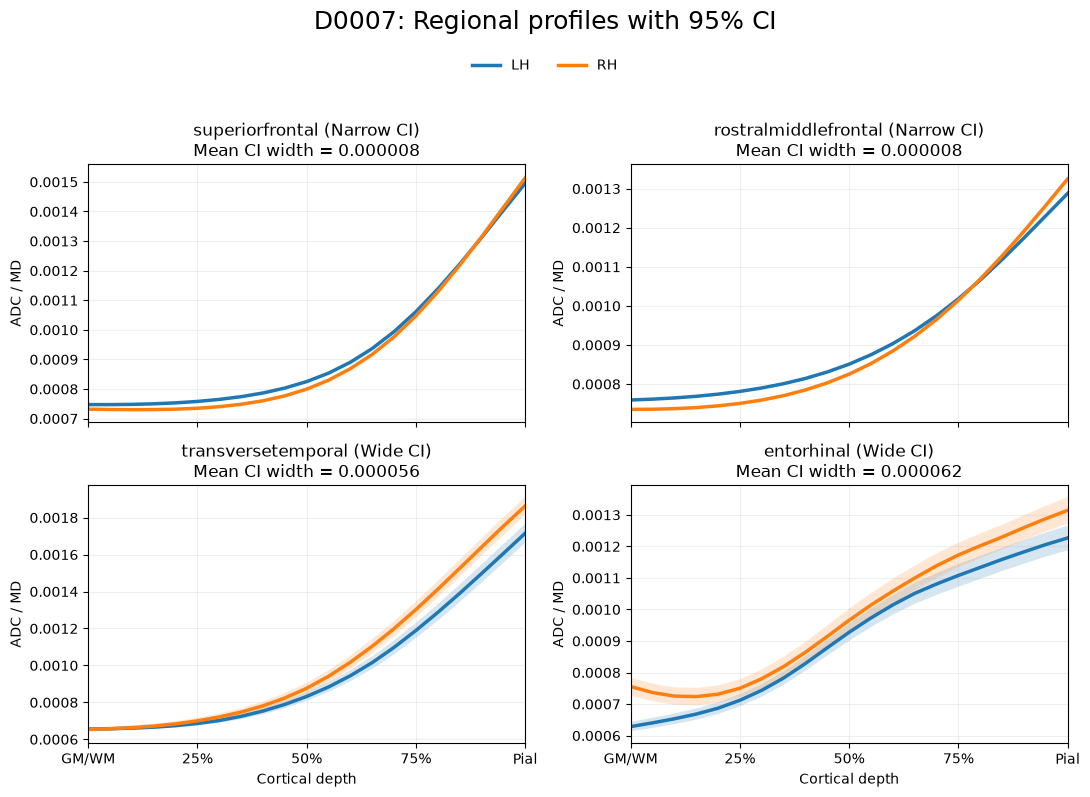

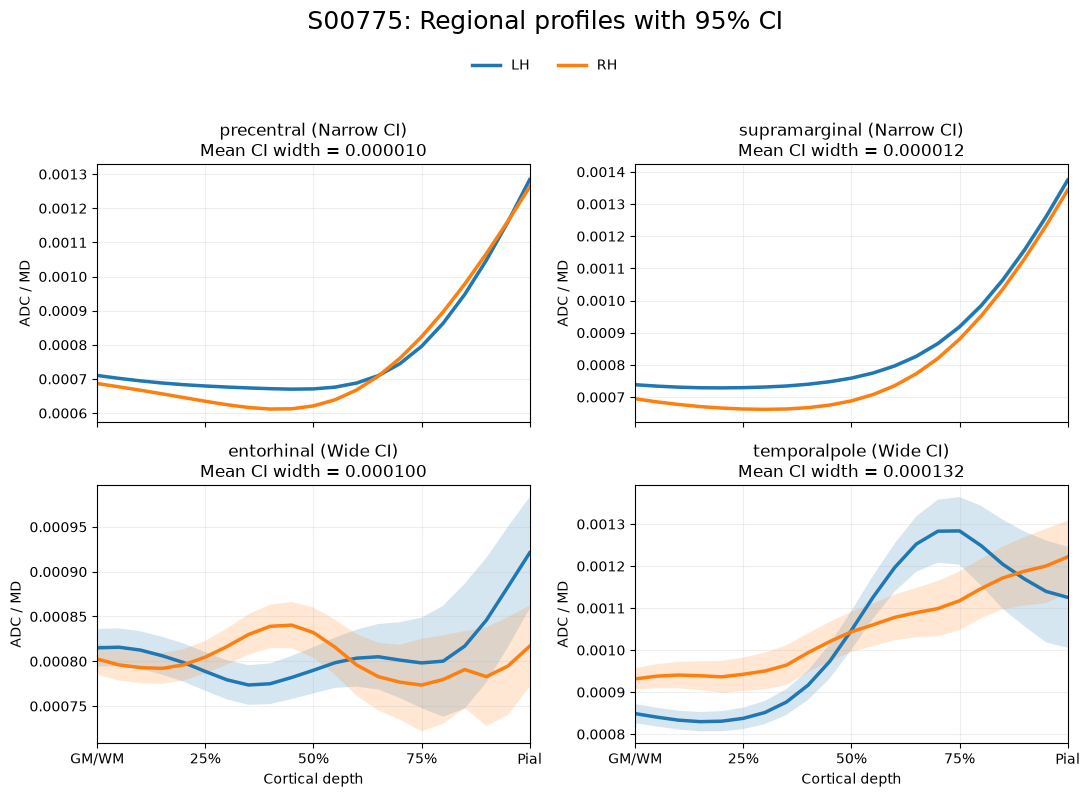

In [167]:
depth = np.linspace(
    0,
    1,
    21,
)

for subject in subjects:

    selected = selected_ci_regions[subject]

    fig, axes = plt.subplots(
        2,
        2,
        figsize=(11, 8),
        sharex=True,
    )

    axes = axes.ravel()

    for ax, (_, row) in zip(
        axes,
        selected.iterrows(),
    ):

        region = row["region"]
        group = row["group"]
        mean_ci_width = row["mean_ci_width"]

        region_df = (
            qa_data[subject][
                qa_data[subject]["region"]
                == region
            ]
        )

        for hemi in ["lh", "rh"]:

            hemi_df = (
                region_df[
                    region_df["hemi"]
                    == hemi
                ]
                .sort_values(
                    "depth_index"
                )
            )

            mean_profile = (
                hemi_df["mean"]
                .to_numpy()
            )

            ci_lower = (
                hemi_df["ci_lower"]
                .to_numpy()
            )

            ci_upper = (
                hemi_df["ci_upper"]
                .to_numpy()
            )

            ax.fill_between(
                depth,
                ci_lower,
                ci_upper,
                alpha=0.18,
            )

            ax.plot(
                depth,
                mean_profile,
                linewidth=2.5,
                label=hemi.upper(),
            )

        ax.set_title(
            f"{region} ({group})\n"
            f"Mean CI width = {mean_ci_width:.6f}"
        )

        ax.set_ylabel(
            "ADC / MD"
        )

        ax.set_xlim(
            0,
            1,
        )

        ax.set_xticks(
            [
                0,
                0.25,
                0.5,
                0.75,
                1,
            ]
        )

        ax.set_xticklabels(
            [
                "GM/WM",
                "25%",
                "50%",
                "75%",
                "Pial",
            ]
        )

        ax.grid(
            alpha=0.2
        )

    axes[2].set_xlabel(
        "Cortical depth"
    )

    axes[3].set_xlabel(
        "Cortical depth"
    )

    handles, labels = (
        axes[0].get_legend_handles_labels()
    )

    fig.suptitle(
        f"{subject}: Regional profiles with 95% CI",
        fontsize=18,
        y=0.99,
    )

    fig.legend(
        handles,
        labels,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.945),
        ncol=2,
        frameon=False,
        fontsize=7.5,
        labelspacing=.35,
        handlelength=1.8,
        handletextpad=.5,
    )

    plt.tight_layout(
        rect=[0, 0, 1, 0.92]
    )

    plt.show()

### Non-positive MD trajectory QC

Mean diffusivity should not be negative. Trajectories containing non-positive MD
values are therefore flagged for further inspection.

This check identifies:

- trajectories containing at least one MD value ≤ 0
- the number and percentage of affected trajectories
- the cortical depths at which non-positive values occur

In [168]:
affected_region_rows = []

for subject in subjects:

    regions = sorted(
        qa_data[subject]["region"].unique()
    )

    for region in regions:

        for hemi in [
            "lh",
            "rh",
        ]:

            profiles = load_profiles(
                subject,
                hemi,
                region,
                metric="adc",
            )

            total = profiles.shape[0]

            affected = np.sum(
                np.any(
                    profiles <= 0,
                    axis=1,
                )
            )

            affected_region_rows.append(
                {
                    "subject":
                        subject,

                    "hemi":
                        hemi,

                    "region":
                        region,

                    "total_trajectories":
                        total,

                    "affected_trajectories":
                        affected,

                    "affected_pct":
                        affected
                        / total
                        * 100,
                }
            )

affected_region_qc = pd.DataFrame(
    affected_region_rows
)

In [169]:
for subject in subjects:

    ranking = (
        affected_region_qc[
            affected_region_qc["subject"]
            == subject
        ]
        .sort_values(
            "affected_pct",
            ascending=False,
        )
        .head(10)
    )

    print(
        f"\n===== {subject}: Highest affected trajectory percentage ====="
    )

    display(
        ranking.style.format(
            {
                "affected_pct": "{:.4f}",
            }
        )
    )


===== D0007: Highest affected trajectory percentage =====


,subject,hemi,region,total_trajectories,affected_trajectories,affected_pct
17,D0007,rh,inferiortemporal,3453,120,3.4752
9,D0007,rh,entorhinal,661,14,2.1180
16,D0007,lh,inferiortemporal,3925,62,1.5796
64,D0007,lh,temporalpole,622,7,1.1254
20,D0007,lh,isthmuscingulate,1302,13,0.9985
31,D0007,rh,middletemporal,3911,16,0.4091
34,D0007,lh,parahippocampal,1011,4,0.3956
45,D0007,rh,postcentral,6049,23,0.3802
8,D0007,lh,entorhinal,664,2,0.3012
30,D0007,lh,middletemporal,3186,7,0.2197



===== S00775: Highest affected trajectory percentage =====


,subject,hemi,region,total_trajectories,affected_trajectories,affected_pct
133,S00775,rh,temporalpole,526,90,17.1103
85,S00775,rh,inferiortemporal,3630,577,15.8953
132,S00775,lh,temporalpole,496,76,15.3226
84,S00775,lh,inferiortemporal,3919,416,10.6150
76,S00775,lh,entorhinal,585,61,10.4274
90,S00775,lh,lateraloccipital,6667,629,9.4345
77,S00775,rh,entorhinal,491,40,8.1466
91,S00775,rh,lateraloccipital,6212,461,7.4211
81,S00775,rh,fusiform,3905,167,4.2766
94,S00775,lh,lingual,4074,132,3.2401


# Whole-brain summary

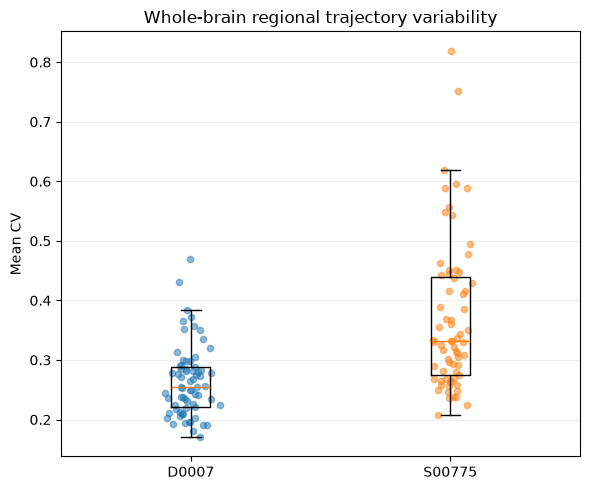

In [171]:
fig, ax = plt.subplots(
    figsize=(6, 5)
)

data = []
labels = []

for subject in subjects:

    values = (
        regional_variability[
            regional_variability["subject"]
            == subject
        ]["mean_cv"]
        .dropna()
        .values
    )

    data.append(values)
    labels.append(subject)

ax.boxplot(
    data,
    tick_labels=labels,
    showfliers=False,
)

for i, values in enumerate(
    data,
    start=1,
):

    x = np.random.normal(
        i,
        0.04,
        size=len(values),
    )

    ax.scatter(
        x,
        values,
        alpha=0.5,
        s=20,
    )

ax.set_ylabel(
    "Mean CV"
)

ax.set_title(
    "Whole-brain regional trajectory variability"
)

ax.grid(
    axis="y",
    alpha=0.2,
)

plt.tight_layout()
plt.show()

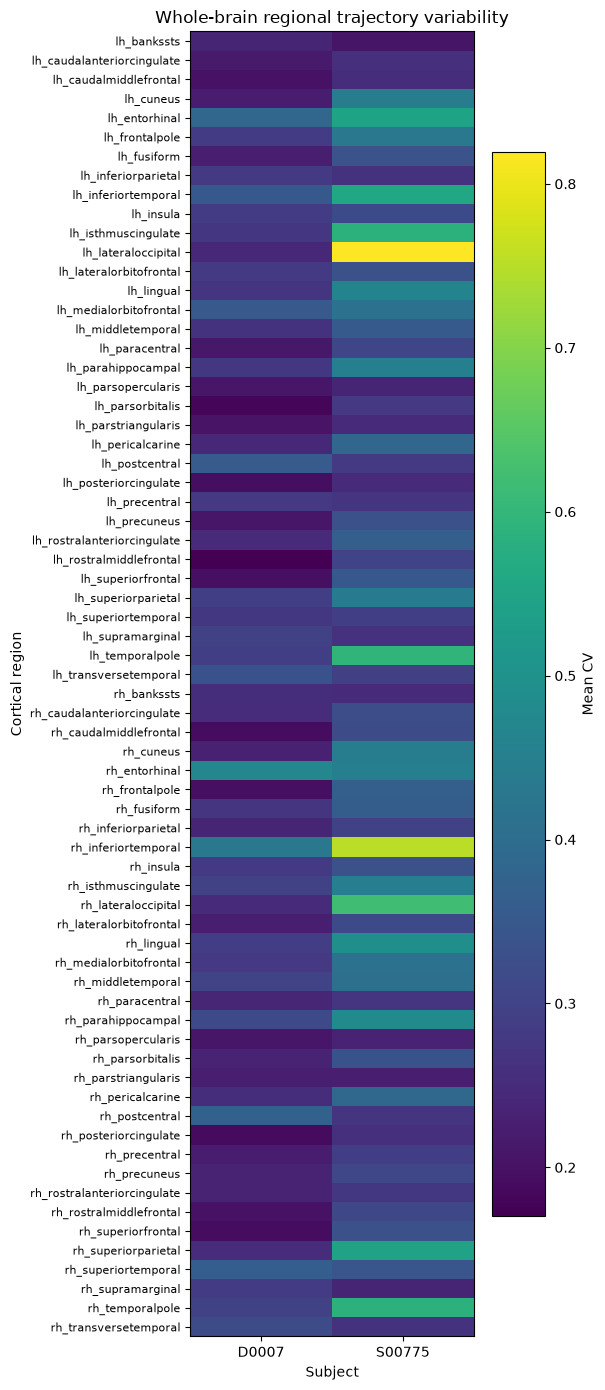

In [174]:
cv_heatmap = (
    regional_variability
    .copy()
)

cv_heatmap["region_hemi"] = (
    cv_heatmap["hemi"]
    + "_"
    + cv_heatmap["region"]
)

cv_matrix = (
    cv_heatmap
    .pivot(
        index="region_hemi",
        columns="subject",
        values="mean_cv",
    )
)

cv_matrix = cv_matrix[
    [
        subject
        for subject in subjects
        if subject in cv_matrix.columns
    ]
]

fig, ax = plt.subplots(
    figsize=(6, 14)
)

im = ax.imshow(
    cv_matrix.values,
    aspect="auto",
)

ax.set_xticks(
    np.arange(
        len(cv_matrix.columns)
    )
)

ax.set_xticklabels(
    cv_matrix.columns
)

ax.set_yticks(
    np.arange(
        len(cv_matrix.index)
    )
)

ax.set_yticklabels(
    cv_matrix.index,
    fontsize=8,
)

ax.set_title(
    "Whole-brain regional trajectory variability"
)

ax.set_xlabel(
    "Subject"
)

ax.set_ylabel(
    "Cortical region"
)

cbar = fig.colorbar(
    im,
    ax=ax,
)

cbar.set_label(
    "Mean CV"
)

plt.tight_layout()
plt.show()

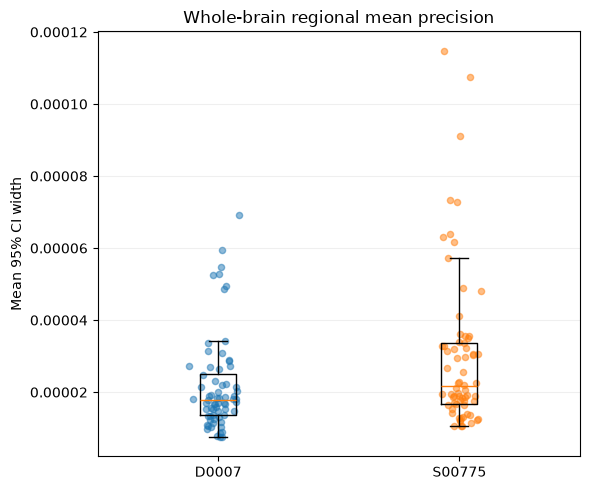

In [173]:
fig, ax = plt.subplots(
    figsize=(6, 5)
)

data = []
labels = []

for subject in subjects:

    values = (
        regional_ci[
            regional_ci["subject"]
            == subject
        ]["mean_ci_width"]
        .dropna()
        .values
    )

    data.append(values)
    labels.append(subject)

ax.boxplot(
    data,
    tick_labels=labels,
    showfliers=False,
)

for i, values in enumerate(
    data,
    start=1,
):

    x = np.random.normal(
        i,
        0.04,
        size=len(values),
    )

    ax.scatter(
        x,
        values,
        alpha=0.5,
        s=20,
    )

ax.set_ylabel(
    "Mean 95% CI width"
)

ax.set_title(
    "Whole-brain regional mean precision"
)

ax.grid(
    axis="y",
    alpha=0.2,
)

plt.tight_layout()
plt.show()

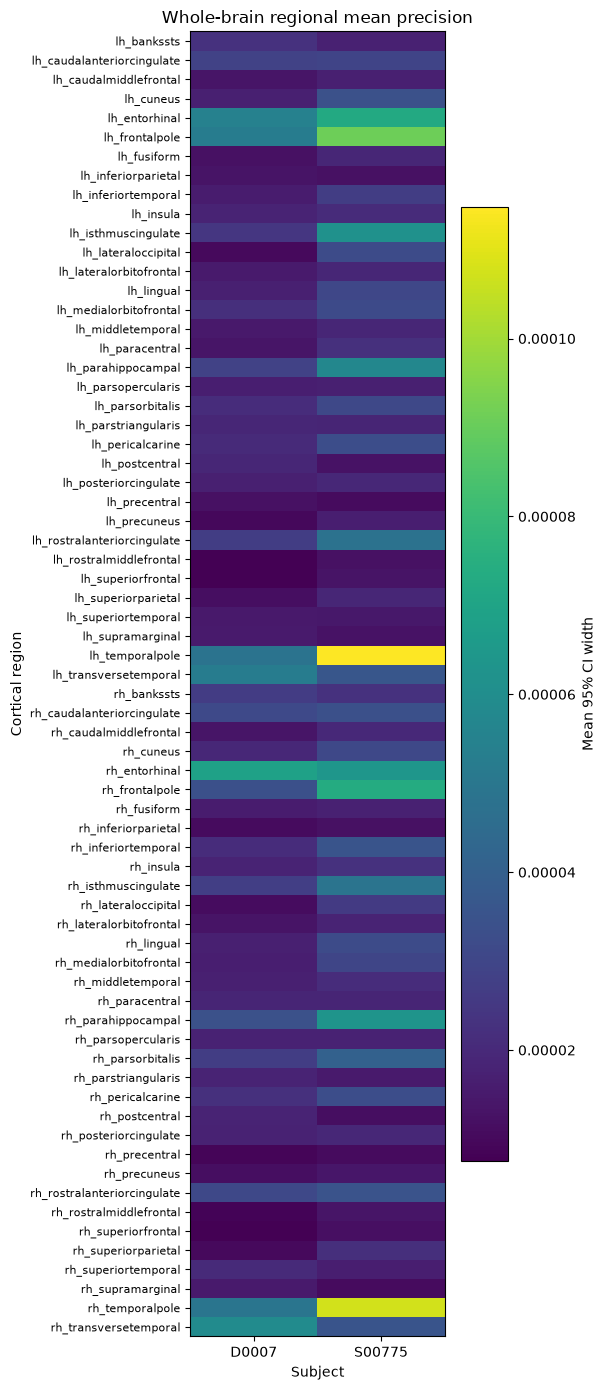

In [176]:
ci_heatmap = (
    regional_ci
    .copy()
)

ci_heatmap["region_hemi"] = (
    ci_heatmap["hemi"]
    + "_"
    + ci_heatmap["region"]
)

ci_matrix = (
    ci_heatmap
    .pivot(
        index="region_hemi",
        columns="subject",
        values="mean_ci_width",
    )
)

ci_matrix = ci_matrix[
    [
        subject
        for subject in subjects
        if subject in ci_matrix.columns
    ]
]

fig, ax = plt.subplots(
    figsize=(6, 14)
)

im = ax.imshow(
    ci_matrix.values,
    aspect="auto",
)

ax.set_xticks(
    np.arange(
        len(ci_matrix.columns)
    )
)

ax.set_xticklabels(
    ci_matrix.columns
)

ax.set_yticks(
    np.arange(
        len(ci_matrix.index)
    )
)

ax.set_yticklabels(
    ci_matrix.index,
    fontsize=8,
)

ax.set_title(
    "Whole-brain regional mean precision"
)

ax.set_xlabel(
    "Subject"
)

ax.set_ylabel(
    "Cortical region"
)

cbar = fig.colorbar(
    im,
    ax=ax,
)

cbar.set_label(
    "Mean 95% CI width"
)

plt.tight_layout()
plt.show()